# In-class work 2. From a raw plant export to an analysis-ready table

Industrial AI, KBTU. Goes with Lecture 2.

Data: **AI4I 2020**, 10 000 cycles of a milling machine. The notebook downloads it from Kaggle.

The file arrives clean, and a file from a real historian never does. So we look at the data,
break it the way plant exports are usually broken, and then repair it step by step:
duplicates, types, gaps, outliers, resampling, scaling, PCA. Every step is a line of pandas or
scikit-learn that you will reuse in the practice.

Run it top to bottom with `Shift+Enter`. The outputs you see were produced by exactly these
cells.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import sklearn

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

KAGGLE = {
    'ai4i': 'stephanmatzka/predictive-maintenance-dataset-ai4i-2020',
}


def dataset_folder(name):
    """The folder with the files of a data set: the Kaggle copy (downloaded once, then cached),
    or data/<name>/ of the course repo if Kaggle is out of reach."""
    if KAGGLE[name]:
        try:
            import contextlib, io, logging, kagglehub
            logging.getLogger("kagglehub").setLevel(logging.ERROR)
            with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
                folder = Path(kagglehub.dataset_download(KAGGLE[name]))
            print(f"{name}: Kaggle {KAGGLE[name]}")
            return folder
        except Exception as exc:
            print(f"Kaggle unavailable ({type(exc).__name__}), looking for data/{name}/")
    for root in [Path.cwd(), *Path.cwd().parents]:
        if (root / "data" / name).is_dir():
            return root / "data" / name
    raise FileNotFoundError(f"no data/{name}/ here or above; run data/fetch.py in the course repo")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | scipy 1.18.1 | sklearn 1.9.1


## 1. Load and look

Rule one: never trust a file you have not printed.

In [2]:
clean = pd.read_csv(dataset_folder("ai4i") / "ai4i2020.csv", encoding="utf-8-sig")
print(clean.shape)          # (rows, columns)
clean.head()

ai4i: Kaggle stephanmatzka/predictive-maintenance-dataset-ai4i-2020
(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.100,308.600,1551,42.800,0,0,0,0,0,0,0
1,2,L47181,L,298.200,308.700,1408,46.300,3,0,0,0,0,0,0
2,3,L47182,L,298.100,308.500,1498,49.400,5,0,0,0,0,0,0
3,4,L47183,L,298.200,308.600,1433,39.500,7,0,0,0,0,0,0
4,5,L47184,L,298.200,308.700,1408,40.000,9,0,0,0,0,0,0


In [3]:
clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

One row is one production cycle of the milling machine. The columns:

| column | meaning |
|---|---|
| `UDI`, `Product ID` | row id and part id |
| `Type` | product quality: `L` low (60 %), `M` medium (30 %), `H` high (10 %) |
| `Air temperature [K]` | workshop air, a random walk around 300 K |
| `Process temperature [K]` | tool temperature, air + 10 K |
| `Rotational speed [rpm]` | spindle speed |
| `Torque [Nm]` | spindle torque |
| `Tool wear [min]` | minutes the tool has already cut |
| `Machine failure` | 1 if the cycle failed |
| `TWF HDF PWF OSF RNF` | which of the five failure modes fired |

The five modes are TWF (tool wear), HDF (heat dissipation), PWF (power), OSF (overstrain) and
RNF (random).

In [4]:
clean.describe().T

,count,mean,std,min,25%,50%,75%,max
UDI,"10,000.000","5,000.500","2,886.896",1.000,"2,500.750","5,000.500","7,500.250","10,000.000"
Air temperature [K],"10,000.000",300.005,2.000,295.300,298.300,300.100,301.500,304.500
Process temperature [K],"10,000.000",310.006,1.484,305.700,308.800,310.100,311.100,313.800
Rotational speed [rpm],"10,000.000","1,538.776",179.284,"1,168.000","1,423.000","1,503.000","1,612.000","2,886.000"
Torque [Nm],"10,000.000",39.987,9.969,3.800,33.200,40.100,46.800,76.600
Tool wear [min],"10,000.000",107.951,63.654,0.000,53.000,108.000,162.000,253.000
Machine failure,"10,000.000",0.034,0.181,0.000,0.000,0.000,0.000,1.000
TWF,"10,000.000",0.005,0.068,0.000,0.000,0.000,0.000,1.000
HDF,"10,000.000",0.011,0.107,0.000,0.000,0.000,0.000,1.000
PWF,"10,000.000",0.009,0.097,0.000,0.000,0.000,0.000,1.000


`describe()` is the cheapest sanity check there is. Read it as four questions:

- Is `count` the same for every column? If not, there are gaps.
- Are `min` and `max` inside the physical range of the sensor? 0 rpm on a running spindle is
  a fault code, not a measurement.
- Are `mean` and `50%` far apart? Then the column is skewed and the mean is not a typical value.
- Is `std` zero? Then the sensor is stuck.

In [5]:
MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

print("categorical columns")
print(clean["Type"].value_counts(), "\n")

print("failures")
print(f"  machine failure : {clean['Machine failure'].sum():5d}"
      f"  ({clean['Machine failure'].mean():.2%} of all cycles)")
for mode in MODES:
    print(f"  {mode:15s} : {clean[mode].sum():5d}  ({clean[mode].mean():.2%})")

categorical columns
Type
L    6000
M    2997
H    1003
Name: count, dtype: int64 

failures
  machine failure :   339  (3.39% of all cycles)
  TWF             :    46  (0.46%)
  HDF             :   115  (1.15%)
  PWF             :    95  (0.95%)
  OSF             :    98  (0.98%)
  RNF             :    19  (0.19%)


3.39 % of the cycles are failures. This number decides a lot later on: a model that always
says "no failure" is already 96.6 % accurate and useless. Remember it when you pick a metric
for SIS-1.

In [6]:
SENSORS = ["Air temperature [K]", "Process temperature [K]",
           "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
# short labels for the plots
SHORT = ["Air T\nK", "Process T\nK", "Speed\nrpm", "Torque\nN·m", "Tool wear\nmin"]

print(clean[SENSORS].agg(["min", "max", "mean", "std"]).T)

                              min       max      mean     std
Air temperature [K]       295.300   304.500   300.005   2.000
Process temperature [K]   305.700   313.800   310.006   1.484
Rotational speed [rpm]  1,168.000 2,886.000 1,538.776 179.284
Torque [Nm]                 3.800    76.600    39.987   9.969
Tool wear [min]             0.000   253.000   107.951  63.654


## 2. The five distributions

Before any cleaning: what shape is each sensor?

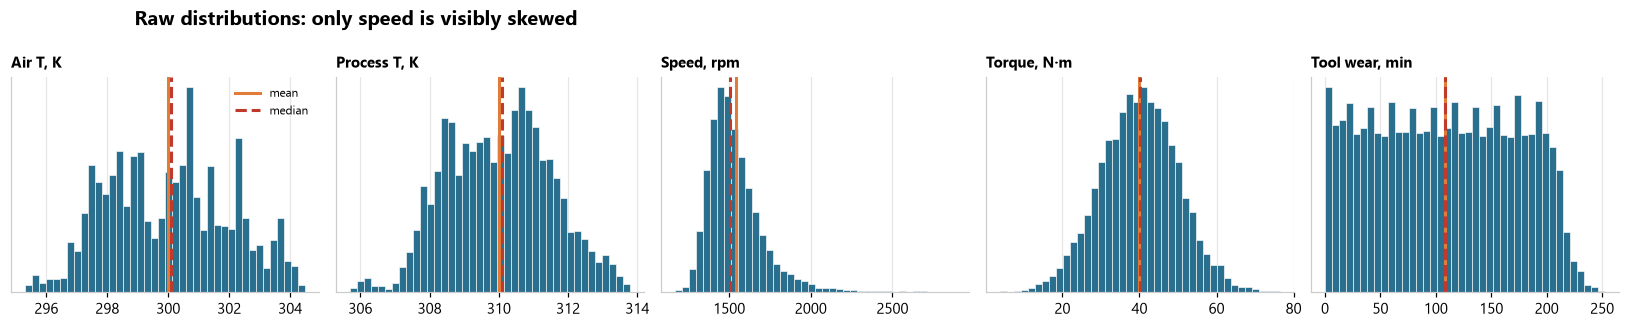

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.0))
for ax, col, name in zip(axes, SENSORS, SHORT):
    ax.hist(clean[col], bins=40, color=BLUE, edgecolor="white", linewidth=0.4)
    ax.set_title(name.replace("\n", ", "), fontsize=10)
    ax.set_yticks([])
    ax.axvline(clean[col].mean(), color=ORANGE, lw=2, label="mean")
    ax.axvline(clean[col].median(), color=RED, lw=2, ls="--", label="median")
axes[0].legend(fontsize=8)
fig.suptitle("Raw distributions: only speed is visibly skewed", x=0.09, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

Four of them are symmetric, with the mean and the median on top of each other. Rotational
speed has a long right tail and its mean lies above its median. That one fact will make the
3-sigma rule and the IQR rule disagree in section 7.

Next, how the sensors move together. The correlation of two columns $\mathbf{x}$ and
$\mathbf{y}$ is

$$r = \frac{(\mathbf{x} - \bar x)^\top (\mathbf{y} - \bar y)}{\lVert \mathbf{x} - \bar x \rVert \, \lVert \mathbf{y} - \bar y \rVert}.$$

Geometrically it is the cosine of the angle between the two centred columns, seen as vectors
with one entry per cycle. $r = \pm 1$ means the vectors are parallel: one column is a straight
line of the other. $r = 0$ means they are orthogonal, with no linear relation.

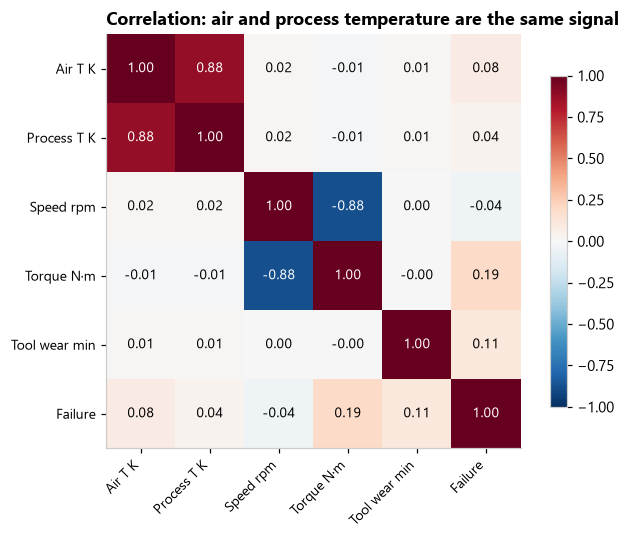

In [8]:
corr = clean[SENSORS + ["Machine failure"]].corr()

fig, ax = plt.subplots(figsize=(6.4, 5.0))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
labels = [s.replace("\n", " ") for s in SHORT] + ["Failure"]
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(labels)), labels, fontsize=9)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = corr.iloc[i, j]
        text_colour = "white" if abs(v) > 0.55 else "black"     # readable on a dark cell
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color=text_colour)
ax.grid(False)
ax.set_title("Correlation: air and process temperature are the same signal")
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
plt.show()

Three things to take away.

- Air T and process T correlate at 0.88. Two sensors carry roughly one piece of information,
  which is what PCA is for (section 10).
- Speed and torque correlate at −0.88. That is physics: the drive holds the power roughly
  constant, so $P = M\omega$ forces the speed down when the torque goes up.
- No single sensor correlates with failure above 0.2. Failures live in combinations of
  sensors, which is why the plant needs a model and not a threshold on one tag.

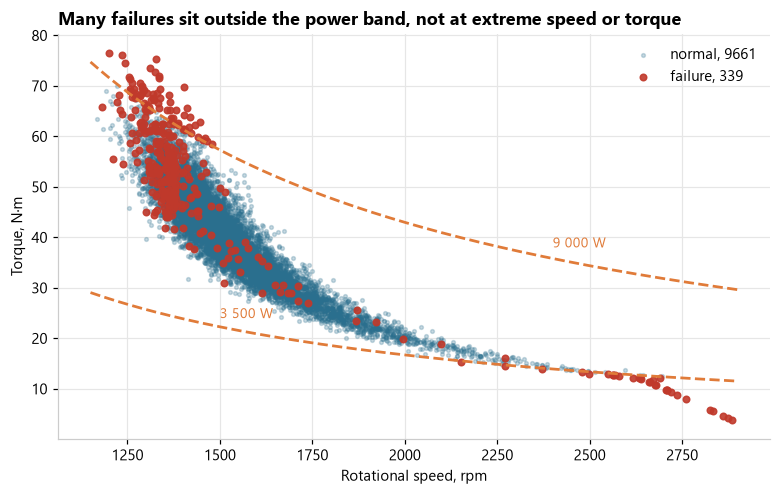

In [9]:
ok = clean["Machine failure"] == 0
bad = ~ok

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.scatter(clean.loc[ok, "Rotational speed [rpm]"], clean.loc[ok, "Torque [Nm]"],
           s=6, c=BLUE, alpha=0.25, label=f"normal, {ok.sum()}")
ax.scatter(clean.loc[bad, "Rotational speed [rpm]"], clean.loc[bad, "Torque [Nm]"],
           s=18, c=RED, alpha=0.9, label=f"failure, {bad.sum()}")

# constant-power curves: P = M * omega with omega = 2*pi*rpm/60, so M = P / omega
rpm = np.linspace(1150, 2900, 200)
for power in [3500, 9000]:                                   # W
    torque = power / (2 * np.pi * rpm / 60)
    ax.plot(rpm, torque, color=ORANGE, ls="--", lw=1.8)
ax.text(2400, 38, "9 000 W", color=ORANGE, fontsize=9)
ax.text(1500, 24, "3 500 W", color=ORANGE, fontsize=9)

ax.set(xlabel="Rotational speed, rpm", ylabel="Torque, N·m",
       title="Many failures sit outside the power band, not at extreme speed or torque")
ax.legend()
fig.tight_layout()
plt.show()

Many red points cluster on both sides of the working band. That is the `PWF` rule from the
description of the data set: a cycle fails when the mechanical power leaves 3 500–9 000 W.
Neither speed nor torque alone shows it; their product does. That is feature engineering, and
Lecture 3 spends an hour on it.

## 3. Breaking it on purpose

AI4I 2020 arrives clean. A file from a real historian never does, so we break this one in the
eight usual ways and spend the rest of the notebook repairing it.

Here you see the damage being done. In the practice you will not.

In [10]:
rng = np.random.default_rng(2026)          # the same damage on every run
raw = clean.copy()


def pick(k):
    # k random row numbers
    return rng.choice(len(raw), k, replace=False)


# one cycle per minute, starting at the morning shift
minutes = pd.date_range("2026-09-01 06:00", periods=len(raw), freq="1min")
raw.insert(1, "timestamp", minutes)

# blank cells: the OPC tag was unavailable
raw.loc[pick(300), "Process temperature [K]"] = np.nan
raw.loc[pick(90), "Tool wear [min]"] = np.nan

# one logger reported air temperature in Celsius instead of Kelvin
raw.loc[pick(150), "Air temperature [K]"] -= 273.15

# a fault code instead of a value
raw.loc[pick(25), "Air temperature [K]"] = -999.0

# a stuck sensor: 60 minutes of the same number
raw.loc[4000:4060, "Air temperature [K]"] = raw.loc[4000, "Air temperature [K]"]

# torque arrived as text, some of it with a comma as the decimal separator
tq = raw["Torque [Nm]"].map("{:.1f}".format)
comma = pick(800)
tq[comma] = tq[comma].str.replace(".", ",", regex=False)
spaces = pick(200)
tq[spaces] = "  " + tq[spaces]
raw["Torque [Nm]"] = tq

# Type was typed by hand at three different stations
ty = raw["Type"].copy()
lower = pick(400)
ty[lower] = ty[lower].str.lower()
padded = pick(300)
ty[padded] = " " + ty[padded] + " "
raw["Type"] = ty

# the link went down: 200 minutes never reached the historian
raw = raw.drop(index=rng.choice(np.arange(2000, 2600), 200, replace=False))

# and the historian polled twice during a hiccup: 120 rows logged again
raw = pd.concat([raw, raw.sample(120, random_state=1)])
raw = raw.sort_values("timestamp").reset_index(drop=True)

print("clean:", clean.shape, " raw:", raw.shape)
raw.head()

clean: (10000, 14)  raw: (9920, 15)


,UDI,timestamp,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,2026-09-01 06:00:00,M14860,M,298.100,308.600,1551,42.8,0.000,0,0,0,0,0,0
1,2,2026-09-01 06:01:00,L47181,L,298.200,308.700,1408,46.3,3.000,0,0,0,0,0,0
2,3,2026-09-01 06:02:00,L47182,L,298.100,308.500,1498,49.4,5.000,0,0,0,0,0,0
3,4,2026-09-01 06:03:00,L47183,L,298.200,308.600,1433,39.5,7.000,0,0,0,0,0,0
4,5,2026-09-01 06:04:00,L47184,L,298.200,308.700,1408,40.0,9.000,0,0,0,0,0,0


In [11]:
# Keep the true values next to the broken ones. We can do this only because we broke the
# file ourselves, and it lets us score every repair later. Join on UDI, never on row
# position: raw now has rows dropped and rows duplicated.
truth = clean.set_index("UDI")
raw["true_air_T"] = raw["UDI"].map(truth["Air temperature [K]"])
raw["true_process_T"] = raw["UDI"].map(truth["Process temperature [K]"])

raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9920 entries, 0 to 9919
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   UDI                      9920 non-null   int64         
 1   timestamp                9920 non-null   datetime64[us]
 2   Product ID               9920 non-null   str           
 3   Type                     9920 non-null   str           
 4   Air temperature [K]      9920 non-null   float64       
 5   Process temperature [K]  9621 non-null   float64       
 6   Rotational speed [rpm]   9920 non-null   int64         
 7   Torque [Nm]              9920 non-null   str           
 8   Tool wear [min]          9829 non-null   float64       
 9   Machine failure          9920 non-null   int64         
 10  TWF                      9920 non-null   int64         
 11  HDF                      9920 non-null   int64         
 12  PWF                      9920 non-null   int6

Read the `Dtype` column. `Torque [Nm]` is now text. `Type` is text, as it should be, but its
values are dirty. `Air temperature [K]` is still a float and still wrong: it holds `-999` and
values in Celsius.

pandas reports a wrong dtype for free. A wrong value inside a correct dtype you have to go and
find.

## 4. Duplicates

Three different things get called a duplicate:

| kind | how it happens | how to find it |
|---|---|---|
| exact copy of a row | the poll ran twice, two files got concatenated | `df.duplicated()` |
| same key, different values | the row was corrected and sent again | `df.duplicated(subset=key)` |
| same timestamp, two tags | two historians merged badly | `df.index.duplicated()` |

In [12]:
print("exact duplicate rows      :", raw.duplicated().sum())
print("duplicate UDI             :", raw.duplicated(subset="UDI").sum())
print("duplicate timestamps      :", raw.duplicated(subset="timestamp").sum())

# what does one of them look like?
d = raw[raw.duplicated(subset="UDI", keep=False)].sort_values("UDI")
d.head(4)

exact duplicate rows      : 120
duplicate UDI             : 120
duplicate timestamps      : 120


,UDI,timestamp,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,true_air_T,true_process_T
234,235,2026-09-01 09:54:00,L47414,L,298.200,308.400,1478,"42,9",183.000,0,0,0,0,0,0,298.200,308.400
235,235,2026-09-01 09:54:00,L47414,L,298.200,308.400,1478,"42,9",183.000,0,0,0,0,0,0,298.200,308.400
590,590,2026-09-01 15:49:00,L47769,L,297.600,NaN,1491,40.2,231.000,0,0,0,0,0,0,297.600,309.400
591,590,2026-09-01 15:49:00,L47769,L,297.600,NaN,1491,40.2,231.000,0,0,0,0,0,0,297.600,309.400


In [13]:
before = len(raw)
raw = raw.drop_duplicates(keep="first").reset_index(drop=True)
print(f"dropped {before - len(raw)} exact duplicates, {len(raw)} rows left")
print("exact duplicates now      :", raw.duplicated().sum())

dropped 120 exact duplicates, 9800 rows left
exact duplicates now      : 0


`keep="first"` keeps the earliest copy. If the second copy is a correction, keep `"last"`
instead. That is a decision about the process, and the operator knows the answer, pandas does
not.

One more check worth doing every time: a column that never changes carries no information.

In [14]:
nunique = raw.nunique()
print(nunique.to_string())
print("\nconstant columns:", list(nunique[nunique <= 1].index) or "none")

UDI                        9800
timestamp                  9800
Product ID                 9800
Type                         11
Air temperature [K]         152
Process temperature [K]      82
Rotational speed [rpm]      940
Torque [Nm]                1072
Tool wear [min]             246
Machine failure               2
TWF                           2
HDF                           2
PWF                           2
OSF                           2
RNF                           2
true_air_T                   93
true_process_T               82

constant columns: none


## 5. Types and units

Repair the types first. You cannot compute anything on text, and half the "gaps" in a real
file are text that failed to parse.

In [15]:
# 5a. text -> float. The comma decimal and the leading spaces both have to go.
tq = (raw["Torque [Nm]"]
      .astype(str)
      .str.strip()                          # "  46,3" -> "46,3"
      .str.replace(",", ".", regex=False))  # "46,3"   -> "46.3"
raw["Torque [Nm]"] = pd.to_numeric(tq, errors="coerce")   # anything left over -> NaN

print("torque dtype:", raw["Torque [Nm]"].dtype)
print("failed to parse:", raw["Torque [Nm]"].isna().sum())

torque dtype: float64
failed to parse: 0


`errors="coerce"` matters here. Without it `to_numeric` raises on the first bad value and you
learn nothing. With it every value it could not read becomes `NaN`, and you can count them.

In [16]:
# 5b. the hand-typed category
print("before:", sorted(raw["Type"].unique()))
raw["Type"] = raw["Type"].astype(str).str.strip().str.upper()
print("after :", sorted(raw["Type"].unique()))
print()
print(raw["Type"].value_counts().to_string())

before: [' H ', ' L ', ' M ', ' l ', ' m ', 'H', 'L', 'M', 'h', 'l', 'm']
after : ['H', 'L', 'M']

Type
L    5878
M    2936
H     986


In [17]:
# 5c. fault codes. Replace the codes you know, not everything that looks small:
# the Celsius rows of 5d are also "small", and unlike -999 they can be recovered.
print("air temperature, smallest values:")
print(raw["Air temperature [K]"].nsmallest(6).to_string())

FAULT_CODES = [-999.0, -9999.0, 32767.0]     # the codes this historian is known to emit
raw["Air temperature [K]"] = raw["Air temperature [K]"].replace(FAULT_CODES, np.nan)
print(f"\nfault codes -> NaN, {raw['Air temperature [K]'].isna().sum()} gaps now")

air temperature, smallest values:
375    -999.000
915    -999.000
1155   -999.000
1538   -999.000
1560   -999.000
1886   -999.000

fault codes -> NaN, 25 gaps now


In [18]:
# 5d. units. Workshop air is 295-305 K; anything between 0 and 100 was logged in Celsius.
air = raw["Air temperature [K]"]
is_celsius = air.between(0, 100)
print(f"{is_celsius.sum()} values look like Celsius")

raw.loc[is_celsius, "Air temperature [K]"] = air[is_celsius] + 273.15
print(f"range now: {raw['Air temperature [K]'].min():.1f} .. "
      f"{raw['Air temperature [K]'].max():.1f} K")

143 values look like Celsius
range now: 295.3 .. 304.5 K


No library does this step for you. A unit check is a physical check: you need to know that the
workshop is around 300 K to see that 26.9 is wrong. Write down the expected range of every tag
before you touch the data. The plant's P&ID or the sensor data sheet has it.

In [19]:
# tag: (low, high), the physical range from the data sheet
LIMITS = {
    "Air temperature [K]":     (290, 315),
    "Process temperature [K]": (300, 320),
    "Rotational speed [rpm]":  (1000, 3000),
    "Torque [Nm]":             (0, 100),
    "Tool wear [min]":         (0, 300),
}
assert set(LIMITS) == set(SENSORS), "every sensor needs a range, only sensors have one"

report = {}
for col, (lo, hi) in LIMITS.items():
    s = raw[col]
    report[col] = {"n": int(s.notna().sum()),
                   "missing": int(s.isna().sum()),
                   "below": int((s < lo).sum()),
                   "above": int((s > hi).sum()),
                   "min": s.min(),
                   "max": s.max()}
pd.DataFrame.from_dict(report, orient="index")

,n,missing,below,above,min,max
Air temperature [K],9775,25,0,0,295.300,304.500
Process temperature [K],9505,295,0,0,305.700,313.800
Rotational speed [rpm],9800,0,0,0,"1,168.000","2,886.000"
Torque [Nm],9800,0,0,0,3.800,76.600
Tool wear [min],9711,89,0,0,0.000,253.000


## 6. Missing values

### 6.1 Find them

Two questions per column: how many, and where.

In [20]:
na = raw.isna().sum()
na = na[na > 0].sort_values(ascending=False)
gaps = pd.DataFrame({"missing": na, "share": (na / len(raw)).map("{:.2%}".format)})
gaps

,missing,share
Process temperature [K],295,3.01%
Tool wear [min],89,0.91%
Air temperature [K],25,0.26%


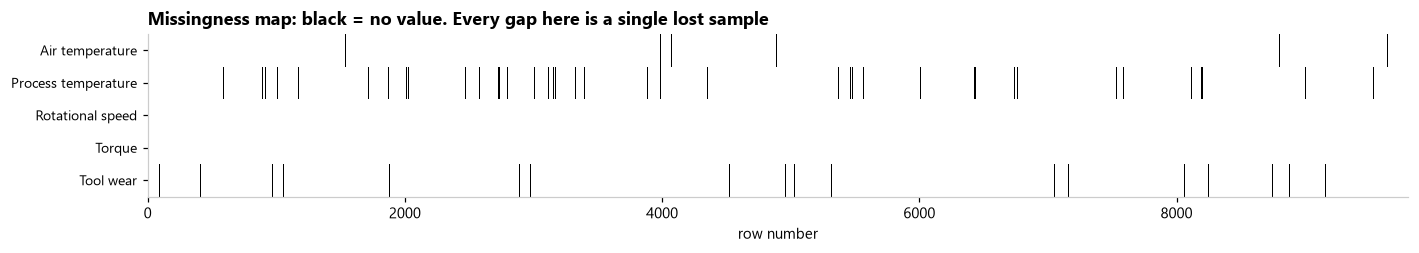

In [21]:
# where the gaps sit is more useful than how many there are
def missing_map(df, title):
    mask = df[SENSORS].isna().to_numpy().T          # (sensor, row), True = no value
    names = [c.split(" [")[0] for c in SENSORS]

    fig, ax = plt.subplots(figsize=(13, 2.4))
    ax.imshow(mask, aspect="auto", cmap="Greys", interpolation="nearest",
              extent=[0, len(df), len(SENSORS) - 0.5, -0.5])
    ax.set_yticks(range(len(SENSORS)), names, fontsize=9)
    ax.set(xlabel="row number", title=title)
    ax.grid(False)
    fig.tight_layout()
    plt.show()


missing_map(raw, "Missingness map: black = no value. "
                 "Every gap here is a single lost sample")

Scattered dots and a solid block mean different things, and the map tells them apart faster
than any number.

Three names decide whether you may fill the gaps at all:

- **MCAR**, missing completely at random: the gap has nothing to do with any value. A dropped
  OPC packet. Fill freely.
- **MAR**, missing at random: the gap depends on other columns. The logger drops samples while
  the line is stopped. Fill, using those columns.
- **MNAR**, missing not at random: the gap depends on the missing value itself. The sensor
  returns nothing above 300 °C. Do not fill: you would hide exactly the events you were hired
  to find.

Either way, record that the value was missing before you fill it.

In [22]:
raw["air_was_missing"] = raw["Air temperature [K]"].isna().astype(int)
print(raw.groupby("air_was_missing")["Machine failure"].agg(["count", "mean"]))

                 count  mean
air_was_missing             
0                 9775 0.034
1                   25 0.000


### 6.2 Fill them

Six ways, cheapest first.

In [23]:
s = raw["Process temperature [K]"]

filled = pd.DataFrame({
    "raw":           s,
    "drop":          s.dropna(),                      # loses rows
    "mean":          s.fillna(s.mean()),
    "median":        s.fillna(s.median()),
    "ffill":         s.ffill(),                       # hold the last value, as a PLC does
    "interpolate":   s.interpolate(method="linear"),  # straight line across the gap
    "rolling":       s.fillna(s.rolling(21, center=True, min_periods=1).mean()),
})

summary = filled.agg(["count", "mean", "std", "min", "max"]).T
summary["count"] = summary["count"].astype(int)
summary

,count,mean,std,min,max
raw,9505,310.032,1.488,305.700,313.800
drop,9505,310.032,1.488,305.700,313.800
mean,9800,310.032,1.466,305.700,313.800
median,9800,310.034,1.466,305.700,313.800
ffill,9800,310.031,1.487,305.700,313.800
interpolate,9800,310.031,1.487,305.700,313.800
rolling,9800,310.031,1.487,305.700,313.800


The means barely move: the gaps here are MCAR, so nothing is biased. The standard deviation is
where the damage shows. Filling a share $q$ of the values with the column mean adds points with
zero deviation, so the variance drops to about $(1-q)\,\sigma^2$. Here $q$ is 3 %, and the
`mean` and `median` rows have a slightly smaller std. On a column with 30 % gaps the same fill
would shrink the std by 16 %. `interpolate` and `rolling` keep the spread.

Every model you fit afterwards reads a shrunk column as quieter and more reliable than it is.

In [24]:
# We know the truth, so score each method on the rows that were actually missing.
gap = s.isna()

scores = {}
for name in ["mean", "median", "ffill", "interpolate", "rolling"]:
    err = filled[name][gap] - raw["true_process_T"][gap]
    scores[name] = {"MAE, K": err.abs().mean(),
                    "RMSE, K": np.sqrt((err ** 2).mean()),
                    "bias, K": err.mean()}
pd.DataFrame.from_dict(scores, orient="index")

,"MAE, K","RMSE, K","bias, K"
mean,1.183,1.447,0.018
median,1.179,1.449,0.086
ffill,0.057,0.080,-0.003
interpolate,0.041,0.057,-0.004
rolling,0.077,0.099,0.004


On a slow, smooth signal like a temperature, interpolation beats the column mean many times
over, and `ffill` is close behind. The reason is the size of the steps. Between two neighbouring
minutes the temperature changes by a small fraction of its total spread, so a neighbour is a far
better guess than the average over the whole log. On a fast, noisy signal the ranking would be
much closer, and there the median of a window is the safer choice. Two rules hold in general:

- for a time series use `interpolate` or `ffill`, because neighbouring samples are the best
  estimate you have;
- for independent rows use the `median`, because there is no neighbour to borrow from.

`ffill` is what the control system itself does when a tag goes bad, so it also reproduces what
the operator saw on the HMI. Sometimes that is what you want.

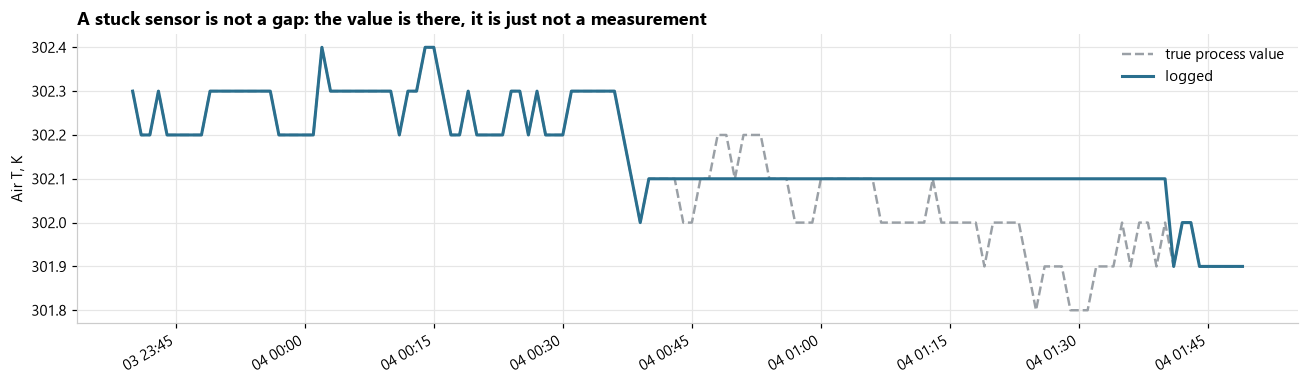

In [25]:
# find the flat block instead of hard-coding where it is
# flat is the largest step over the last 30 minutes: 0 means no change at all
step = raw["Air temperature [K]"].diff().abs()
flat = step.rolling(30).max()
centre = int(flat[flat == 0].index[0])
seg = slice(centre - 90, centre + 40)
t = raw["timestamp"][seg]

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(t, raw["true_air_T"][seg], color=GREY, ls="--", lw=1.6,
        label="true process value")
ax.plot(t, raw["Air temperature [K]"][seg], color=BLUE, lw=2, label="logged")
title = "A stuck sensor is not a gap: the value is there, it is just not a measurement"
ax.set(ylabel="Air T, K", title=title)
ax.legend()
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

`isna()` will never find this. A stuck tag is found by asking whether the value changed:

31 rows inside a 30-minute window with zero change
first at row 3830 -> 2026-09-04 01:10:00
stuck block marked as missing, now 85 gaps


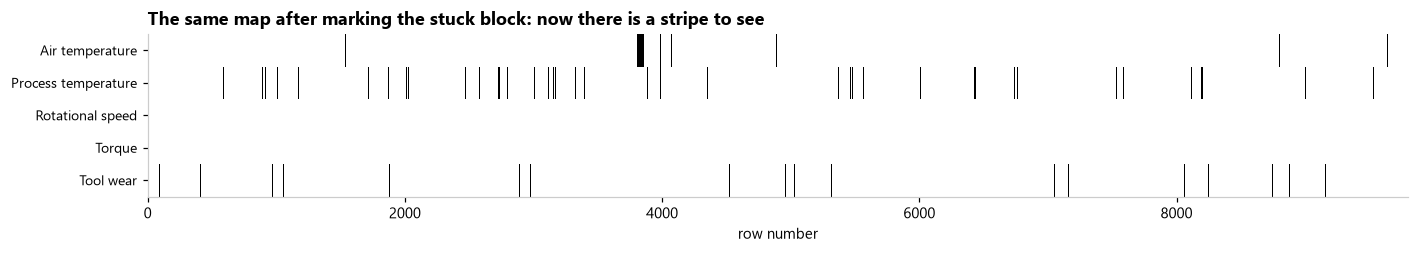

In [26]:
stuck_rows = flat[flat == 0]
first = stuck_rows.index[0]
print(f"{len(stuck_rows)} rows inside a 30-minute window with zero change")
print("first at row", first, "->", raw['timestamp'].iloc[first])

# each flagged row closes a 30-row window, so the block starts 29 rows before the first
block_start = stuck_rows.index.min() - 29
block_end = stuck_rows.index.max()
raw.loc[block_start:block_end, "Air temperature [K]"] = np.nan
n_gaps = raw["Air temperature [K]"].isna().sum()
print("stuck block marked as missing, now", n_gaps, "gaps")

missing_map(raw, "The same map after marking the stuck block: "
                 "now there is a stripe to see")

In [27]:
# apply the decisions to the whole table
FILL = {
    "Air temperature [K]":     "interpolate",
    "Process temperature [K]": "interpolate",
    "Rotational speed [rpm]":  "interpolate",
    "Torque [Nm]":             "interpolate",
    "Tool wear [min]":         "ffill",     # wear only ever grows; holding it is honest
}
for col, how in FILL.items():
    if how == "interpolate":
        raw[col] = raw[col].interpolate(method="linear")
    else:
        raw[col] = raw[col].ffill()

raw[SENSORS] = raw[SENSORS].bfill()   # a gap in row 0 has nothing to its left
print("gaps left:", int(raw[SENSORS].isna().sum().sum()))

gaps left: 0


## 7. Outliers

Three rules, one line of code each.

**3-sigma.** Keep $\mu - 3\sigma \le x \le \mu + 3\sigma$. On a normal distribution this band
holds 99.73 % of the values, so 0.27 % get flagged. The weakness: $\mu$ and $\sigma$ are
computed from the data including the outliers. One point at distance $d$ from the mean adds
about $d^2/n$ to the variance, so a few wild points inflate $\sigma$, widen the band, and hide
themselves.

**IQR (Tukey).** With $\mathrm{IQR} = Q_3 - Q_1$, keep
$Q_1 - 1.5\,\mathrm{IQR} \le x \le Q_3 + 1.5\,\mathrm{IQR}$. Quartiles do not care how far the
far points are, so the rule is robust. On a normal distribution $Q_{1,3} = \mu \mp 0.674\sigma$,
so the fences sit at $\mu \pm 2.70\sigma$ and flag about 0.7 %. On a skewed column they flag
much more.

**Robust z-score.** The 3-sigma rule rebuilt from the median and the median absolute deviation
$\mathrm{MAD} = \mathrm{median}\,|x - \mathrm{med}|$:
$z = 0.6745\,(x - \mathrm{med})/\mathrm{MAD}$, flag $|z| > 3.5$. For normal data
$\mathrm{MAD} = 0.6745\,\sigma$, so the factor turns MAD into an estimate of $\sigma$.

**Why is the IQR multiplier 1.5 and not 1 or 2?**

<details><summary>Answer</summary>

Nothing derives it: Tukey picked a round number and checked what it does on normal data. With
$Q_{1,3} = \mu \mp 0.674\sigma$ and $\mathrm{IQR} = 1.349\sigma$, a multiplier $k$ puts the upper
fence at $(0.674 + 1.349\,k)\,\sigma$:

| $k$ | fence | share of normal data flagged |
|---|---|---|
| 1 | $2.02\sigma$ | 4.3 % |
| 1.5 | $2.70\sigma$ | 0.70 % |
| 2 | $3.37\sigma$ | 0.075 % |

With $k = 1$ one healthy value in 23 gets flagged, too many to look at. With $k = 1.5$ the fence
lands close to the familiar $3\sigma$ and flags 0.7 %. Tukey also used $k = 3$ for "far out"
values, $4.72\sigma$, which a normal law produces about twice in a million.

</details>

In [28]:
# each rule returns (mask of flagged values, (low fence, high fence))
def three_sigma(s, k=3.0):
    mu = s.mean()
    sd = s.std()
    low = mu - k * sd
    high = mu + k * sd
    return (s < low) | (s > high), (low, high)


def iqr_rule(s, k=1.5):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    low = q1 - k * iqr
    high = q3 + k * iqr
    return (s < low) | (s > high), (low, high)


def robust_z(s, k=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    z = 0.6745 * (s - med) / mad
    low = med - k * mad / 0.6745
    high = med + k * mad / 0.6745
    return z.abs() > k, (low, high)


counts = {}
for col in SENSORS:
    s = raw[col]
    name = col.split(" [")[0]
    counts[name] = {"skew": s.skew(),
                    "3-sigma": int(three_sigma(s)[0].sum()),
                    "IQR": int(iqr_rule(s)[0].sum()),
                    "robust z": int(robust_z(s)[0].sum())}
pd.DataFrame.from_dict(counts, orient="index")

,skew,3-sigma,IQR,robust z
Air temperature,0.091,0,0,0
Process temperature,-0.021,0,0,0
Rotational speed,1.998,161,405,264
Torque,-0.004,25,70,6
Tool wear,0.025,0,0,0


Read the skew column next to the counts. Where the skew is near zero, the rules agree, and on
the two temperatures they agree on flagging nothing at all. Rotational speed has a skew of +2.0,
and there the IQR rule flags 405 cycles against 161 for 3-sigma, two and a half times as many.

Neither rule is wrong. 3-sigma asks whether a value is far from the mean in units of the
spread, and the long right tail has already inflated that spread. IQR asks whether a value is
far outside the middle half, and the quartiles never saw the tail. On a skewed column, trust
IQR.

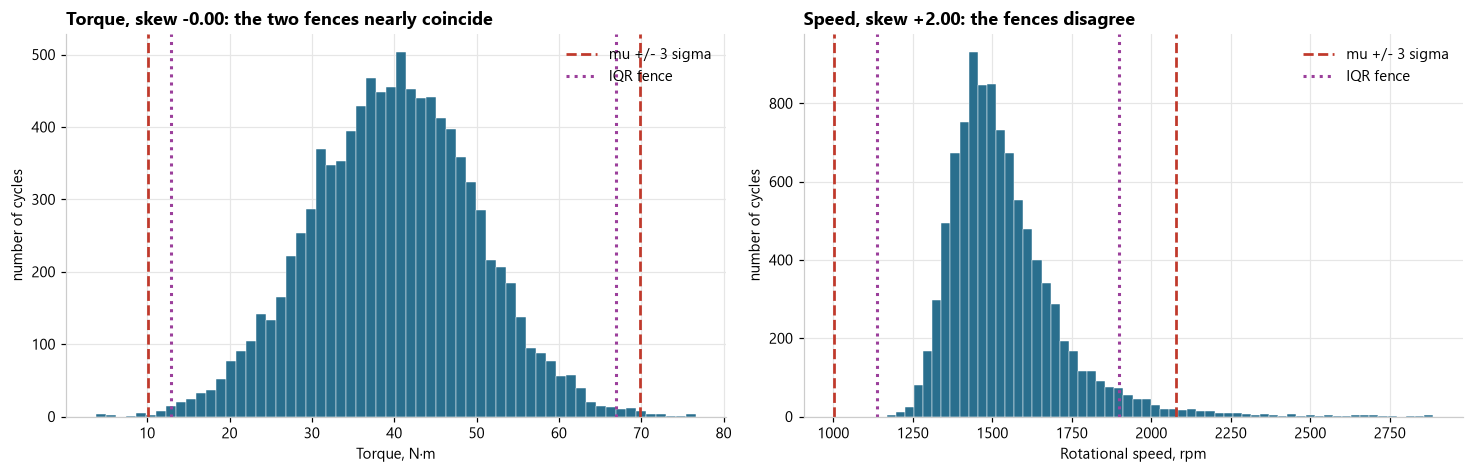

In [29]:
tq, sp = raw["Torque [Nm]"], raw["Rotational speed [rpm]"]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
panels = [(axes[0], tq, "Torque, N·m"), (axes[1], sp, "Rotational speed, rpm")]
for ax, s, name in panels:
    lim3 = three_sigma(s)[1]
    limi = iqr_rule(s)[1]
    ax.hist(s, bins=60, color=BLUE, edgecolor="white", linewidth=0.3)
    ax.axvline(lim3[0], color=RED, ls="--", lw=1.8, label="mu +/- 3 sigma")
    ax.axvline(lim3[1], color=RED, ls="--", lw=1.8)
    ax.axvline(limi[0], color=PURPLE, ls=":", lw=2.0, label="IQR fence")
    ax.axvline(limi[1], color=PURPLE, ls=":", lw=2.0)
    ax.set(xlabel=name, ylabel="number of cycles")
    ax.legend()

axes[0].set(title=f"Torque, skew {tq.skew():+.2f}: the two fences nearly coincide")
axes[1].set(title=f"Speed, skew {sp.skew():+.2f}: the fences disagree")
fig.tight_layout()
plt.show()

### The part that matters on a plant

An outlier is a statistical statement: this value is far from the others. Whether it is an
error is an engineering statement, and no formula knows the difference.

In [30]:
flagged, _ = iqr_rule(raw["Rotational speed [rpm]"])
fail = raw["Machine failure"] == 1
flagged_failures = (flagged & fail).sum()
rate_inside = raw.loc[~flagged, "Machine failure"].mean()
rate_flagged = raw.loc[flagged, "Machine failure"].mean()

print(f"IQR flags {flagged.sum()} cycles on speed")
print(f"  of them, failures : {flagged_failures}")
print(f"failure rate inside the fence : {rate_inside:.2%}")
print(f"failure rate among flagged    : {rate_flagged:.2%}")
print()
print(f"drop the flagged rows and you lose {flagged_failures} of {fail.sum()} failures "
      f"= {flagged_failures / fail.sum():.0%} of the positives")

IQR flags 405 cycles on speed
  of them, failures : 35
failure rate inside the fence : 3.19%
failure rate among flagged    : 8.64%

drop the flagged rows and you lose 35 of 335 failures = 10% of the positives


Deleting statistical outliers from a failure data set deletes the failures. The flagged cycles
fail at 8.6 % against 3.2 % inside the fence, nearly three times as often. Those points are the
signal, and the IQR rule found them without being told what a failure is.

So flag, and do not delete, unless you can name the physical reason why the value is
impossible.

| what you found | what to do |
|---|---|
| outside the sensor's physical range | drop or set to `NaN`: it is not a measurement |
| a fault code (`-999`, `32767`, `0` on a running drive) | `NaN` |
| a single-sample spike with normal neighbours | median filter |
| far from the mean but physically possible | keep the row, add a flag column |
| a whole shifted block | a separate operating mode: model it, do not clip it |

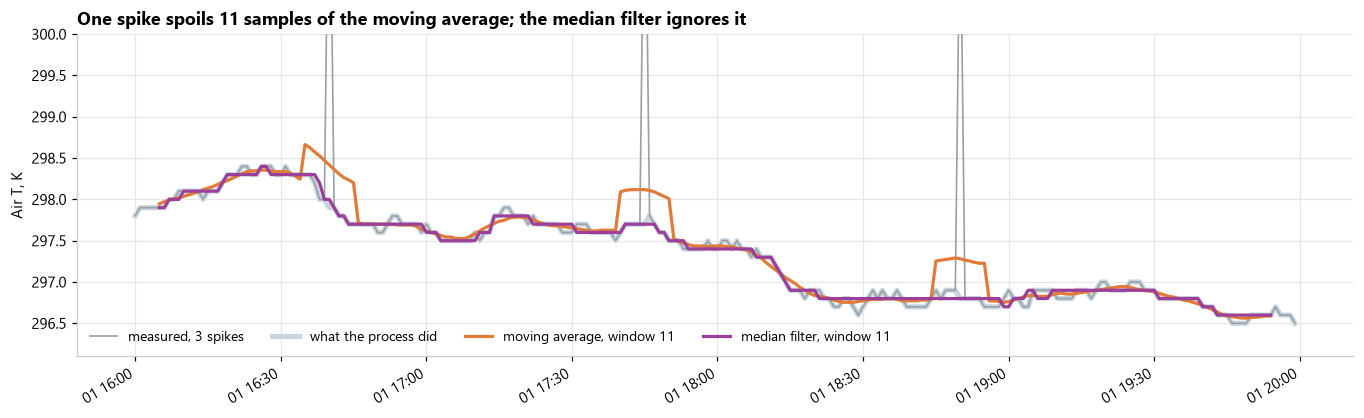

In [31]:
raw["speed_outlier"] = flagged.astype(int)     # keep the information, keep the rows

# A spike is a different animal: a real measurement error, one sample wide.
# Air temperature is smooth, so the two filters can be told apart on it.
w = slice(600, 840)
clean_air = raw["Air temperature [K]"].iloc[w].reset_index(drop=True)
noisy = clean_air.copy()
noisy.iloc[[40, 105, 170]] += 5.0                # three contact-bounce spikes, K

moving_average = noisy.rolling(11, center=True).mean()
moving_median = noisy.rolling(11, center=True).median()

t = raw["timestamp"].iloc[w].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12.5, 3.9))
ax.plot(t, noisy, color=GREY, lw=1.1, label="measured, 3 spikes")
ax.plot(t, clean_air, color="#c7d6de", lw=3.4, zorder=0, label="what the process did")
ax.plot(t, moving_average, color=ORANGE, lw=2.1, label="moving average, window 11")
ax.plot(t, moving_median, color=PURPLE, lw=2.1, label="median filter, window 11")
title = ("One spike spoils 11 samples of the moving average; "
         "the median filter ignores it")
ylim = (clean_air.min() - 0.4, clean_air.max() + 1.6)      # room above for the spikes
ax.set(ylabel="Air T, K", ylim=ylim, title=title)
ax.legend(ncol=4, fontsize=9)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

That is slide 7 of the lecture in three lines of pandas. A moving average of width $w$ spreads a
spike of height $h$ into a bump of height $h/w$ across $w$ samples: here a 5 K spike becomes
0.45 K over eleven minutes. The median of the same window ignores one extreme value as long as
fewer than half the window are spikes, so the spike simply disappears.

## 8. Resampling

The log has one row per minute while the link is up, and section 3 knocked a hole in it.
Models want a regular grid, so we put the data on one.

In [32]:
ts = raw.set_index("timestamp").sort_index()

steps = ts.index.to_series().diff()
print("gaps between consecutive rows:")
print(steps.value_counts().head(4).to_string())

duration = ts.index.max() - ts.index.min()
span = int(duration.total_seconds() // 60) + 1
print(f"\nspan {ts.index.min()} .. {ts.index.max()}")
print(f"minutes in that span : {span}")
print(f"rows we actually have: {len(ts)}")

gaps between consecutive rows:
timestamp
0 days 00:01:00    9660
0 days 00:02:00      96
0 days 00:03:00      28
0 days 00:04:00      13

span 2026-09-01 06:00:00 .. 2026-09-08 04:39:00
minutes in that span : 10000
rows we actually have: 9800


In [33]:
# asfreq puts the index on a fixed grid and turns the holes into NaN
minute = ts[SENSORS].asfreq("1min")
print("rows on the 1-minute grid:", len(minute))
print("holes exposed            :", int(minute["Torque [Nm]"].isna().sum()))

# resample aggregates instead, and the aggregation you pick changes the answer
hour = ts[SENSORS].resample("1h").agg(["mean", "max", "std"])
hour.head(3)

rows on the 1-minute grid: 10000
holes exposed            : 200


Air temperature [K]               Process temperature [K]               Rotational speed [rpm]        \
                                   mean     max   std                    mean     max   std                   mean   max   
timestamp                                                                                                                  
2026-09-01 06:00:00             298.720 299.100 0.280                 309.106 309.500 0.246              1,547.117  2861   
2026-09-01 07:00:00             298.870 299.100 0.087                 308.868 309.100 0.156              1,558.583  1991   
2026-09-01 08:00:00             298.540 299.000 0.255                 308.353 308.800 0.201              1,514.667  1988   

                            Torque [Nm]               Tool wear [min]                 
                        std        mean    max    std            mean     max    std  
timestamp                                                                             
2026-09-01 06:00:00 235.259      39.853 54.900 10.352          83.217 165.000 49.907  
2026-09-01 07:00:00 155.228      38.023 65.700  9.291          93.600 208.000 68.239  
2026-09-01 08:00:00 164.310      41.645 62.300 10.213         118.733 218.000 69.087

Down-sampling throws information away. Which information depends on the aggregation:

- `mean` keeps the operating point. Spikes vanish.
- `max` and `min` keep the worst case in the interval, which is what an alarm system wants.
- `std` keeps how agitated the signal was, often the most useful number for diagnostics.

With the mean, a two-minute overload disappears. With the max, the normal level disappears.
Keep all three.

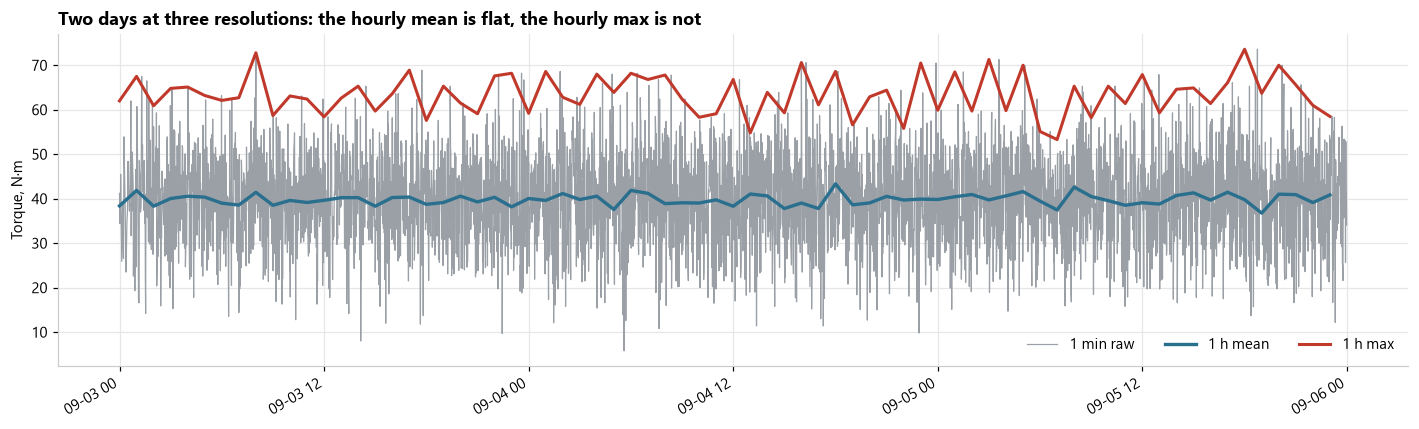

In [34]:
day = slice("2026-09-03", "2026-09-05")
torque_minutes = ts.loc[day, "Torque [Nm]"]
torque_hours = hour.loc[day, "Torque [Nm]"]          # columns mean, max, std

fig, ax = plt.subplots(figsize=(13, 4.0))
ax.plot(torque_minutes.index, torque_minutes, color=GREY, lw=0.8, label="1 min raw")
ax.plot(torque_hours.index, torque_hours["mean"], color=BLUE, lw=2.2, label="1 h mean")
ax.plot(torque_hours.index, torque_hours["max"], color=RED, lw=2.0, label="1 h max")
title = "Two days at three resolutions: the hourly mean is flat, the hourly max is not"
ax.set(ylabel="Torque, N·m", title=title)
ax.legend(ncol=3)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

Up-sampling has the opposite problem: you invent rows. `resample("30s").interpolate()` hands you
a value every 30 seconds that no sensor ever measured. Do it to line two tags up on a common
clock, and never call the extra rows measurements.

## 9. Scaling

Air temperature lives near 300, speed near 1500, torque near 40. Any method that measures a
distance (k-means, k-NN, SVM, PCA, a neural network) hears the speed sensor and little else.
In $\lVert \mathbf{x}_i - \mathbf{x}_j \rVert^2 = \sum_m (x_{im} - x_{jm})^2$ every sensor adds
its squared difference in its own units. A speed difference of one standard deviation, 180 rpm,
contributes $180^2 \approx 32\,000$; an air temperature difference of one standard deviation,
2 K, contributes 4. Scaling makes the sensors comparable.

| method | formula | range after | breaks on |
|---|---|---|---|
| min-max | $x' = \dfrac{x - x_{\min}}{x_{\max} - x_{\min}}$ | $[0, 1]$ | one outlier squashes everything else |
| z-score (standard) | $x' = \dfrac{x - \mu}{\sigma}$ | mean 0, sd 1, unbounded | heavy skew |
| robust | $x' = \dfrac{x - \mathrm{med}}{\mathrm{IQR}}$ | median 0 | rarely anything |
| max-abs | $x' = x / \max|x|$ | $[-1, 1]$ | keeps zeros at zero, good for sparse data |

For industrial sensor data the default is the z-score: PCA needs it, and a single stuck reading
of 32767 would destroy min-max.

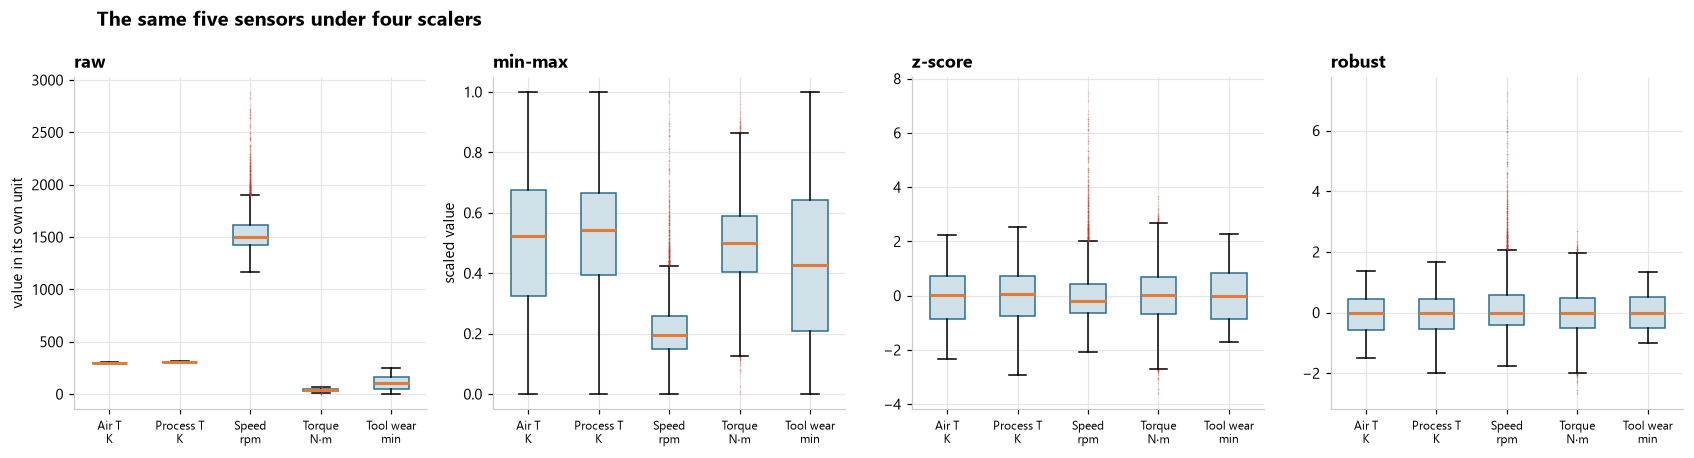

In [35]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

X = raw[SENSORS].to_numpy()

scaled = {
    "raw":      X,
    "min-max":  MinMaxScaler().fit_transform(X),
    "z-score":  StandardScaler().fit_transform(X),
    "robust":   RobustScaler().fit_transform(X),
}

# outliers drawn as small faint red dots
flier_style = dict(marker=".", markersize=2, alpha=0.25,
                   markerfacecolor=RED, markeredgecolor="none")

fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.2))
for ax, (name, M) in zip(axes, scaled.items()):
    bp = ax.boxplot(M, tick_labels=SHORT, patch_artist=True, showfliers=True,
                    flierprops=flier_style)
    for box in bp["boxes"]:
        box.set(facecolor="#cfe0e8", edgecolor=BLUE)
    for med in bp["medians"]:
        med.set(color=ORANGE, linewidth=2)
    ax.set(title=name)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set(ylabel="value in its own unit")
axes[1].set(ylabel="scaled value")
fig.suptitle("The same five sensors under four scalers", x=0.06, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

The first panel shows the problem: on one linear axis, speed is the only sensor you can see.
The other three panels hold the same data in other units.

Now the failure of min-max, measured.

In [36]:
x = raw["Rotational speed [rpm]"].to_numpy(dtype=float)


def minmax(v):
    return (v - v.min()) / (v.max() - v.min())


def iqr(v):
    q3, q1 = np.percentile(v, [75, 25])
    return q3 - q1


broken = x.copy()
broken[0] = 32767.0            # one stuck register, one row out of ten thousand

mm = minmax(x)
mm_bad = minmax(broken)
print(f"min-max, clean data : median {np.median(mm):.3f}, IQR {iqr(mm):.3f}")
print(f"min-max, one bad row: median {np.median(mm_bad):.3f}, IQR {iqr(mm_bad):.3f}")

z = (x - x.mean()) / x.std()
zb = (broken - broken.mean()) / broken.std()
print(f"z-score, clean data : median {np.median(z):+.3f}, sd {z.std():.3f}")
print(f"z-score, one bad row: median {np.median(zb):+.3f}, sd {zb.std():.3f}")

min-max, clean data : median 0.196, IQR 0.111
min-max, one bad row: median 0.011, IQR 0.006
z-score, clean data : median -0.196, sd 1.000
z-score, one bad row: median -0.106, sd 1.000


Min-max takes both of its numbers from the two most extreme values. One bad row out of 10 000
moves $x_{\max}$ from 2886 to 32767, so the denominator $x_{\max} - x_{\min}$ grows about
eighteen-fold. The whole
column lands in the bottom 2 % of the range, and the IQR of the scaled column shrinks from 0.11
to 0.006. The data are still there, but every model now sees a near-constant. The z-score
column is dented and still usable. This is why the hunt for fault codes in section 5 comes
before scaling.

### Fit on the training rows only

The scaler learns $\mu$ and $\sigma$ from data. If it learns them from the test rows too, the
test set has leaked into the model.

In [37]:
from sklearn.model_selection import train_test_split

y = raw["Machine failure"].to_numpy()
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=2026, stratify=y)

sc = StandardScaler().fit(Xtr)                         # fit on the training rows only
Xtr_s, Xte_s = sc.transform(Xtr), sc.transform(Xte)    # transform both

print(f"train mean {Xtr_s.mean(axis=0).round(3)}")
test_mean = Xte_s.mean(axis=0).round(3)
print(f"test  mean {test_mean}   <- close to 0, not exactly 0. Correct.")

train mean [ 0. -0.  0. -0.  0.]
test  mean [ 0.011 -0.004  0.028 -0.018 -0.004]   <- close to 0, not exactly 0. Correct.


If the test means come out at exactly zero, the scaler was fitted on the test set. It is the
most common mistake in student reports: the model scores beautifully in the notebook and fails
on the plant.

## 10. PCA

Five sensors, but air T and process T carry nearly the same signal, and so do speed and
torque. PCA finds the directions along which the data vary and lets you drop the rest.

Write the standardised data as a matrix $\mathbf{Z}$, $n$ rows (cycles) by $p$ columns
(sensors). Projecting one cycle $\mathbf{z}$ on a unit vector $\mathbf{w}$ gives the number
$\mathbf{w}^\top \mathbf{z}$. Over all cycles these numbers have variance
$\mathbf{w}^\top \mathbf{C}\,\mathbf{w}$, with $\mathbf{C}$ the covariance matrix. PCA looks for
the $\mathbf{w}$ that makes this variance largest under $\lVert \mathbf{w} \rVert = 1$. Setting
the gradient of the Lagrangian $\mathbf{w}^\top \mathbf{C}\mathbf{w} - \lambda(\mathbf{w}^\top
\mathbf{w} - 1)$ to zero gives

$$\mathbf{C}\,\mathbf{w} = \lambda\,\mathbf{w},$$

so the best directions are the eigenvectors of $\mathbf{C}$, and the variance along each is
$\mathbf{w}^\top \mathbf{C}\mathbf{w} = \lambda$, its eigenvalue. The recipe from the lecture:

1. Standardise. Otherwise PCA describes the sensor with the biggest units instead of the
   process.
2. Compute the covariance matrix $\mathbf{C} = \frac{1}{n}\mathbf{Z}^\top\mathbf{Z}$, which says
   how the tags move together.
3. Eigen-decompose, $\mathbf{C}\mathbf{v}_i = \lambda_i \mathbf{v}_i$. The eigenvectors
   $\mathbf{v}_i$ are the principal components, the eigenvalues $\lambda_i$ the variance along
   each.
4. Keep the first $k$, enough to add up to the share of the variance you need.

Component $i$ explains $\lambda_i / \sum_j \lambda_j$ of the variance. $\mathbf{C}$ is
symmetric, so its eigenvectors are orthogonal, and the new features are uncorrelated by
construction.

In [38]:
# step 1: standardise (StandardScaler divides by the std with ddof=0)
Z = StandardScaler().fit_transform(raw[SENSORS].to_numpy())
n = len(Z)

# step 2: covariance. Divide by n to match the ddof=0 of the scaler: then the diagonal is
# exactly 1 and C is the correlation matrix.
C = Z.T @ Z / n
names = [s.split(" [")[0] for s in SENSORS]
print("covariance matrix (= correlation matrix, because the data are standardised)")
print(pd.DataFrame(C, index=names, columns=names).round(2).to_string())

# step 3: eigen-decomposition. eigh, not eig: C is symmetric.
lam, vec = np.linalg.eigh(C)
order = np.argsort(lam)[::-1]         # eigh returns them smallest first
lam, vec = lam[order], vec[:, order]

print("\neigenvalues      :", lam.round(3))
print("share of variance:", (lam / lam.sum()).round(3))
print("sum of eigenvalues:", round(lam.sum(), 3), "= trace of C = number of features")

covariance matrix (= correlation matrix, because the data are standardised)
                     Air temperature  Process temperature  Rotational speed  Torque  Tool wear
Air temperature                1.000                0.880             0.020  -0.010      0.010
Process temperature            0.880                1.000             0.020  -0.010      0.010
Rotational speed               0.020                0.020             1.000  -0.870      0.000
Torque                        -0.010               -0.010            -0.870   1.000     -0.000
Tool wear                      0.010                0.010             0.000  -0.000      1.000

eigenvalues      : [1.908 1.844 1.    0.126 0.122]
share of variance: [0.382 0.369 0.2   0.025 0.024]
sum of eigenvalues: 5.0 = trace of C = number of features


In [39]:
from sklearn.decomposition import PCA

pca = PCA().fit(Z)
print("sklearn explained_variance_ratio_:", pca.explained_variance_ratio_.round(3))
print("our eigenvalues / their sum      :", (lam / lam.sum()).round(3))
print("\nthe same numbers: PCA is the eigen-decomposition of the covariance matrix")

sklearn explained_variance_ratio_: [0.382 0.369 0.2   0.025 0.024]
our eigenvalues / their sum      : [0.382 0.369 0.2   0.025 0.024]

the same numbers: PCA is the eigen-decomposition of the covariance matrix


The sum of the eigenvalues is the trace of $\mathbf{C}$, the sum of its diagonal. After
standardising every diagonal entry is one variance equal to 1, so the eigenvalues always add up
to $p = 5$. (scikit-learn divides by $n-1$ instead of $n$. That scales every eigenvalue by the
same factor and leaves the shares unchanged.)

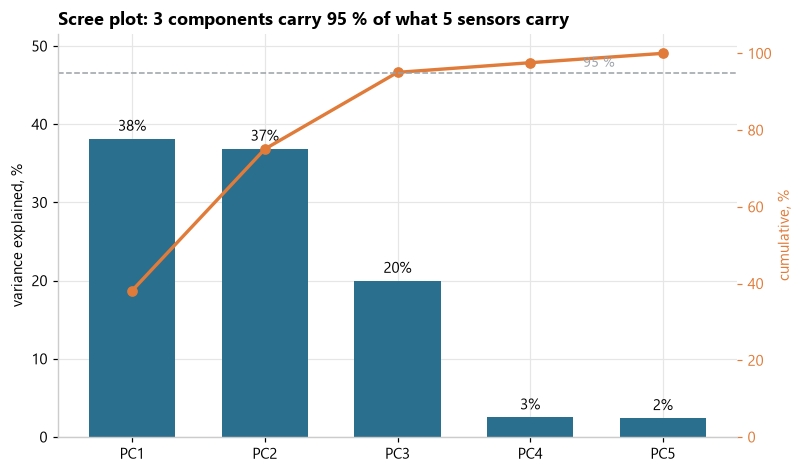

In [40]:
ratio = pca.explained_variance_ratio_ * 100
cum = ratio.cumsum()
pcs = [f"PC{i+1}" for i in range(len(ratio))]

fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.bar(pcs, ratio, color=BLUE, width=0.65)
for i, v in enumerate(ratio):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=10)
ax.set(ylabel="variance explained, %", ylim=(0, max(ratio) * 1.35))

ax2 = ax.twinx()
ax2.plot(pcs, cum, color=ORANGE, marker="o", lw=2.2)
ax2.set_ylabel("cumulative, %", color=ORANGE)
ax2.tick_params(axis="y", colors=ORANGE)
ax2.set_ylim(0, 105)
ax2.grid(False)
ax2.axhline(95, color=GREY, ls="--", lw=1)
ax2.text(3.4, 96.5, "95 %", color=GREY, fontsize=9)

k95 = int(np.searchsorted(cum, 95) + 1)
ax.set_title(f"Scree plot: {k95} components carry 95 % of what 5 sensors carry")
fig.tight_layout()
plt.show()

There are two ways to choose $k$, and a report should say which one it used:

- a variance target: the smallest $k$ whose cumulative share is above 90–95 %;
- the elbow: the point where the bars stop dropping. Here PC4 and PC5 are visibly flat
  leftovers.

For a 2-D picture you take $k = 2$ regardless and report how much variance you kept.

In [41]:
first_three = pca.components_[:3].T          # one column per component
load = pd.DataFrame(first_three, index=names, columns=["PC1", "PC2", "PC3"]).round(3)
load

,PC1,PC2,PC3
Air temperature,0.512,0.488,-0.011
Process temperature,0.510,0.490,-0.013
Rotational speed,0.491,-0.509,-0.004
Torque,-0.487,0.513,0.000
Tool wear,0.015,0.010,1.000


You name a component by reading down its column and looking at the large values.

PC3 is easy: tool wear loads 1.00 and nothing else loads at all. Wear correlates with no other
tag, so PCA hands it back as its own axis.

PC1 and PC2 are not what you would expect. Both load on everything: PC1 is
`+air +process +speed −torque`, PC2 is `+air +process −speed +torque`. The temperature pair and
the speed–torque pair are mixed into both.

The reason is in the eigenvalues, 1.908 and 1.844, almost equal. If two eigenvalues were exactly
equal, every unit vector in the plane of their eigenvectors would satisfy
$\mathbf{C}\mathbf{w} = \lambda\mathbf{w}$ and explain the same variance. The plane is fixed,
but the choice of two axes inside it is not. With nearly equal eigenvalues the choice is decided
by small details of the data, and `eigh` returns one of many almost equivalent rotations.

So a principal component is a direction of variance, and it may or may not be a physical
factor. Sometimes the two coincide, as with PC3. When eigenvalues are close, interpret the pair
together: here PC1 and PC2 together are "thermal state and mechanical load", 75 % of what the
five sensors carry.

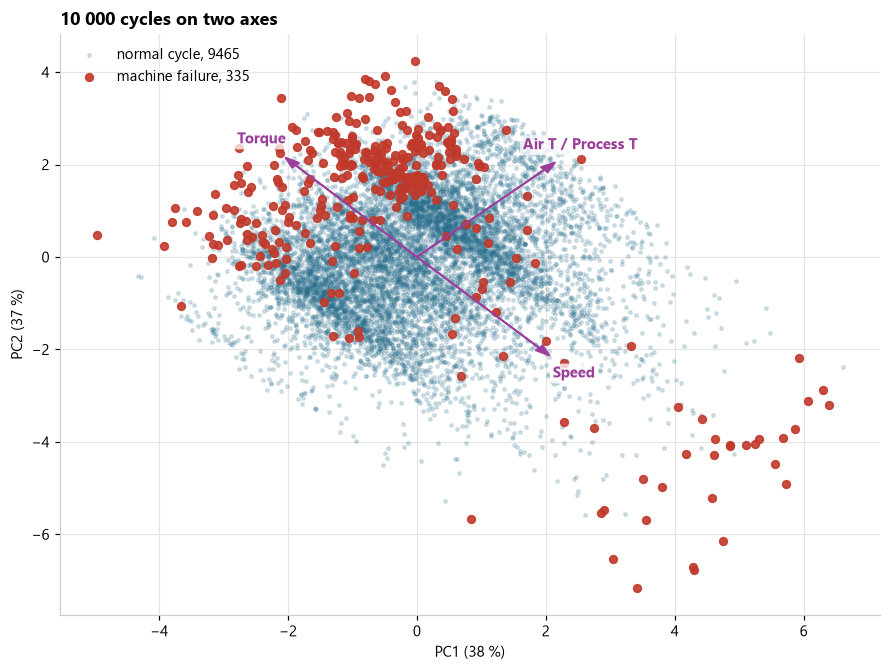

In [42]:
P = pca.transform(Z)[:, :2]
fail = raw["Machine failure"].to_numpy() == 1

fig, ax = plt.subplots(figsize=(8.2, 6.2))
ax.scatter(P[~fail, 0], P[~fail, 1], s=5, c=BLUE, alpha=0.18,
           label=f"normal cycle, {(~fail).sum()}")
ax.scatter(P[fail, 0], P[fail, 1], s=26, c=RED, alpha=0.9,
           label=f"machine failure, {fail.sum()}")

# The loading arrows. Air T and process T point the same way, so they share one label;
# tool wear is left out: it is PC3, so its arrow in this plane has almost no length.
ARROWS = {0: "Air T / Process T", 2: "Speed", 3: "Torque"}    # SENSORS column -> label
label_box = dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.75)

for i, label in ARROWS.items():
    vx = pca.components_[0, i] * 4.2
    vy = pca.components_[1, i] * 4.2
    ax.arrow(0, 0, vx, vy, color=PURPLE, width=0.012, head_width=0.16,
             length_includes_head=True, zorder=4)
    ax.text(vx * 1.18, vy * 1.18, label, color=PURPLE, fontsize=9.5, fontweight="bold",
            ha="center", va="center", zorder=5, bbox=label_box)

ax.set(xlabel=f"PC1 ({ratio[0]:.0f} %)", ylabel=f"PC2 ({ratio[1]:.0f} %)",
       title="10 000 cycles on two axes")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

The arrows are the loadings drawn in the plane: a point far along an arrow has a high value of
that sensor. Torque and speed point in opposite directions, as they must at constant power.

The failures sit on the rim of the cloud, and the top-left group is the high-torque, low-speed
corner: the same power story as in section 2, now visible without anyone telling us the rule.

The failures do not form a separate cluster, and nothing here says PCA can classify them. It
says they are extreme in the plane that the five sensors span. That is enough to build an alarm
on.

The alarm is the **squared prediction error** (SPE, also called the Q statistic). Keep $k$
components in the $p \times k$ matrix $\mathbf{V}_k$. The projection of a cycle onto their plane
is $\mathbf{V}_k \mathbf{V}_k^\top \mathbf{z}$, and the SPE is the squared distance from the
cycle to that plane:

$$\mathrm{SPE}(\mathbf{z}) = \lVert \mathbf{z} - \mathbf{V}_k \mathbf{V}_k^\top \mathbf{z} \rVert^2 .$$

A cycle that follows the usual relations between the sensors lies close to the plane. A cycle
that breaks them, with high torque but no drop in speed for example, lies far from it.

In [43]:
# reconstruction error (SPE): squared distance of each cycle from the 2-component plane
p2 = PCA(n_components=2).fit(Z)
recon = p2.inverse_transform(p2.transform(Z))
spe = ((Z - recon) ** 2).sum(axis=1)

limit = np.percentile(spe, 99)           # alarm on the worst 1 %
alarm = spe > limit

print(f"alarm limit (99th percentile of SPE): {limit:.2f}")
print(f"cycles above it : {alarm.sum()}")
print(f"failure rate among them        : {raw['Machine failure'][alarm].mean():.1%}")
print(f"failure rate among the rest    : {raw['Machine failure'][~alarm].mean():.1%}")
print(f"failures caught by this alarm  : {(alarm & fail).sum()} of {fail.sum()}")

alarm limit (99th percentile of SPE): 3.91
cycles above it : 98
failure rate among them        : 51.0%
failure rate among the rest    : 2.9%
failures caught by this alarm  : 50 of 335


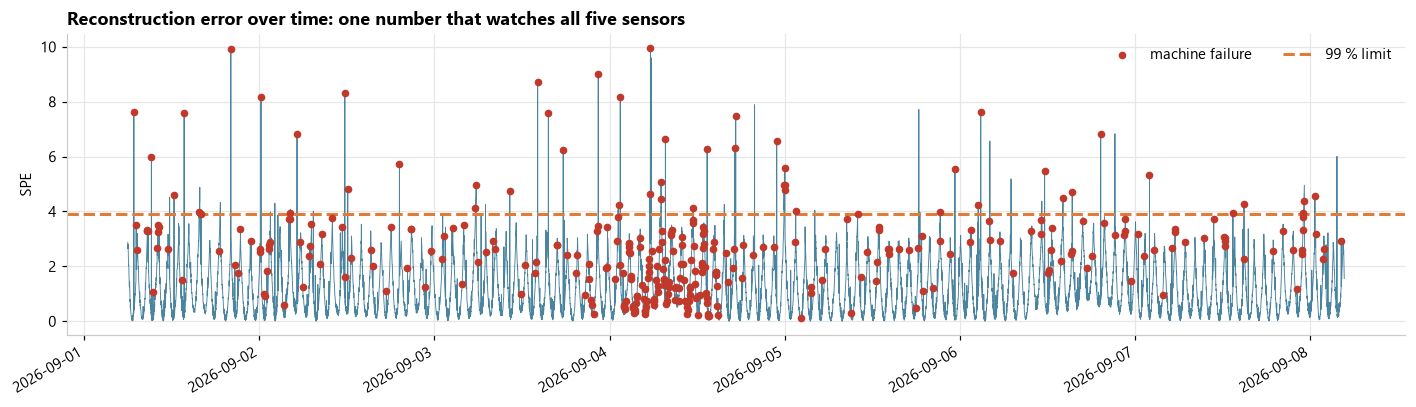

In [44]:
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(raw["timestamp"], spe, color=BLUE, lw=0.6, alpha=0.85)
ax.scatter(raw["timestamp"][fail], spe[fail], s=16, c=RED, zorder=3,
           label="machine failure")
ax.axhline(limit, color=ORANGE, ls="--", lw=2, label="99 % limit")
title = "Reconstruction error over time: one number that watches all five sensors"
ax.set(ylabel="SPE", title=title)
ax.legend(ncol=2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

This is how PCA is used on a plant. You do not ship the scatter plot. You ship one number per
cycle, the distance of the machine from the plane its own history spans, and you raise an alarm
when that number crosses a limit fitted on healthy data. Hundreds of tags collapse into one
trend the operator can watch.

Half the cycles above the limit are failures, against a base rate of 3 %. For a detector that
never saw a single label, that is a lot.

Now look at the shape of the trace rather than the dots. It sawtooths, and the teeth are the
tool wear cycle. We projected onto two components and dropped PC3, and PC3 was tool wear. So
everything wear does now lands in the residual, and the alarm is partly a wear meter. We can
measure that:

In [45]:
by_k = {}
for k in [1, 2, 3, 4]:
    pk = PCA(n_components=k).fit(Z)
    recon_k = pk.inverse_transform(pk.transform(Z))
    spe_k = ((Z - recon_k) ** 2).sum(axis=1)
    alarm_k = spe_k > np.percentile(spe_k, 99)
    by_k[k] = {"variance kept": f"{pk.explained_variance_ratio_.sum():.0%}",
               "alarms": int(alarm_k.sum()),
               "failures caught": int((alarm_k & fail).sum()),
               "precision": f"{raw['Machine failure'][alarm_k].mean():.0%}"}
pd.DataFrame.from_dict(by_k, orient="index").rename_axis("components")

,variance kept,alarms,failures caught,precision
components,,,,
1,38%,98,36,37%
2,75%,98,50,51%
3,95%,98,54,55%
4,98%,98,33,34%


Three components make the better detector: 54 failures caught against 50, on the same budget of
98 alarms, because the wear axis no longer leaks into the residual. Four components are worse
than one. With 98 % of the variance kept, the residual is almost pure noise. Two components make
the nicer picture and three make the better alarm. You do not have to use the same $k$ for both,
but say in the report which one each figure used.

One rule is easy to get wrong: fit the PCA on healthy data only. We fitted on everything, so the
failures helped to define the plane they are supposed to stick out of. In SIS-1, fit the scaler
and the PCA on normal cycles from the training split, then transform everything else with them.

## 11. All of it as one object

Everything above was done by hand so that you could see it. In a report it has to be one object
that you can `fit` on the training rows and `transform` on anything, because that is the only
way the same preprocessing reaches production.

In [46]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

CAT = ["Type"]

numeric = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale",  StandardScaler()),
])

categorical = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

prep = ColumnTransformer([("num", numeric, SENSORS), ("cat", categorical, CAT)])

full = Pipeline([("prep", prep), ("pca", PCA(n_components=3))])

df_tr, df_te = train_test_split(raw, test_size=0.3, random_state=2026,
                                stratify=raw["Machine failure"])
full.fit(df_tr)                                   # learns medians, mu, sigma, components
out = full.transform(df_te)

print("train rows", len(df_tr), "-> test rows", len(df_te))
print("features in :", len(SENSORS) + len(CAT))
print("features out:", out.shape[1])
print("variance kept:", f"{full.named_steps['pca'].explained_variance_ratio_.sum():.1%}")

train rows 6860 -> test rows 2940
features in : 6
features out: 3
variance kept: 85.8%


`full` is one object you can pickle, version and hand over. Add a classifier as the last step
and `full.fit(X, y)` trains the whole chain. `cross_val_score(full, X, y)` refits the imputer and
the scaler inside every fold, which is the only way to cross-validate without leaking.

SIS-1 asks for two habits: write the preprocessing as a `Pipeline` from the start, and keep the
flag columns (`air_was_missing`, `speed_outlier`) as features.

## 12. The short version

| problem | how you find it | usual fix |
|---|---|---|
| duplicate rows | `df.duplicated().sum()` | `drop_duplicates(keep="first")` |
| wrong dtype | `df.info()` | `str.strip`, `str.replace`, `pd.to_numeric(errors="coerce")` |
| fault codes | `df.min()`, `df.max()`, physical range | replace with `NaN` |
| wrong unit | value outside the plant's range | convert, then check again |
| gaps | `df.isna().sum()`, missingness map | time series: `interpolate` / `ffill`; rows: `median` |
| stuck sensor | `diff().abs().rolling(w).max() == 0` | mark the block `NaN`, then fill |
| outliers | 3-sigma, IQR, robust z | flag; drop only if physically impossible |
| spikes | eye, or `diff` | `rolling(w).median()` |
| irregular clock | `index.to_series().diff().value_counts()` | `asfreq` / `resample` |
| different units per tag | `describe()` | `StandardScaler` |
| too many correlated tags | correlation matrix | `PCA`, then name the components |

The order matters, and it is nearly always this one:

**types → duplicates → units and fault codes → gaps → outlier flags → resample → scale → PCA**

Scale before removing the fault codes and you get a scaler fitted on `-999`. Run PCA before
scaling and you get a PCA of the rpm column.

The cleaning sets the ceiling for the model: no architecture from later lectures recovers what
you deleted here.

## Further reading

- Missing-data mechanisms. The names MCAR, MAR and MNAR of section 6.1 come from D. B. Rubin,
  "Inference and missing data", *Biometrika*, 1976. The standard book is R. J. A. Little and
  D. B. Rubin, *Statistical Analysis with Missing Data*, Wiley, 1987. It shows how to check
  whether gaps depend on other columns, and how multiple imputation fills each gap several times
  so that the model sees how unsure the fill is.

---

Next: Practice 1, `practice_1.ipynb`. The same steps on a real pump with 52 sensors, and nobody
tells you what is broken.